# Stellar normalization as a central test

A brief experiment was conducted to assess how differences in stellar mass normalization contribute to cross-simulation inference differences.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / 'pyproject.toml').is_file())
def table(relative):
    return pd.read_csv(ROOT / 'results' / relative)
def saved_json(relative):
    return json.loads((ROOT / 'results' / relative).read_text(encoding='utf-8'))
plt.rcParams.update({'figure.figsize': (9, 4), 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_rows', 40)
pd.set_option('display.max_columns', 16)

The shift is applied to logarithmic TNG stellar inputs **before scaling**. Dynamics and
stellar ratios remain invariant. The grid is -0.10 to +0.60 dex in 0.05 dex steps, plus
an independently calibrated value. The calibration uses only training rows, with the
log summed bound subhalo mass as the response and dynamics, stellar sum and host flag
as predictors. It does not select the shift from held-out M200c errors.

Predictors use a common equal-domain reference. The TNG-minus-FLAMINGO intercept
gap divided by the FLAMINGO stellar slope gives Δ=0.3616893786 dex. Its uncertainty
comes from 500 host-component bootstrap repeats. The held-out comparison uses 2000
paired component resamples. This is a sensitivity experiment, not a recommendation
to change the observed Local Group stellar masses.


definition                training-only bound-mass intercept gap / FLAMI...
bound_gap                                                           0.36338
flamingo_stellar_slope                                             1.004673
delta                                                              0.361689
interval95                        [0.3527423499218308, 0.36930334112245744]
n_flamingo                                                           109150
n_tng                                                                  1169
repeats                                                                 500
dtype: object

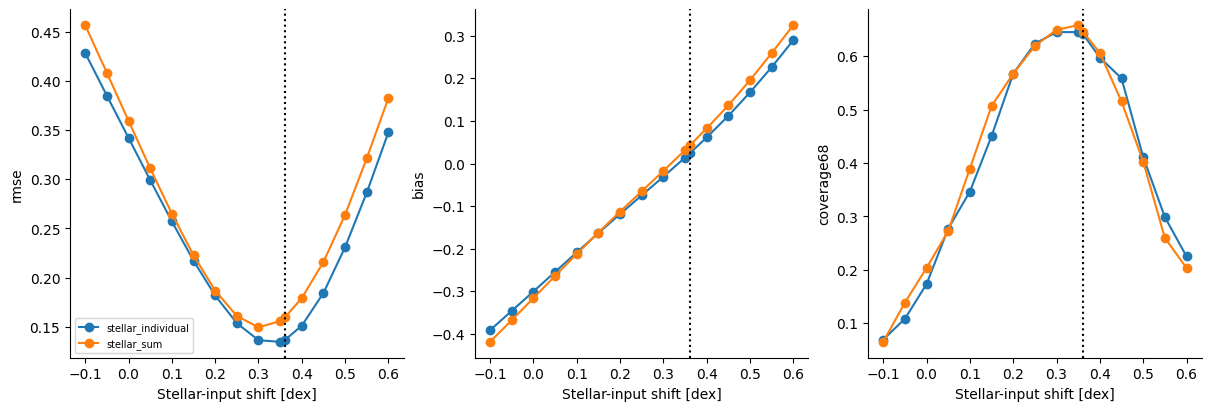

In [2]:
calibration=saved_json('competing/delta_calibration.json')
delta=calibration['bound_gap']/calibration['flamingo_stellar_slope']
assert np.isclose(delta,calibration['delta'],atol=1e-14)
display(pd.Series({k:calibration[k] for k in ['definition','bound_gap','flamingo_stellar_slope','delta','interval95','n_flamingo','n_tng','repeats']}))
values=table('competing/delta_full_sensitivity.csv')
pooled=values.query("subset == 'pooled'")
fig,axes=plt.subplots(1,3,figsize=(12,4),layout='constrained')
for model,part in pooled.groupby('model'):
    part=part.sort_values('delta')
    for ax,metric in zip(axes,['rmse','bias','coverage68']):
        ax.plot(part.delta,part[metric],'o-',label=model)
for ax,metric in zip(axes,['rmse','bias','coverage68']):
    ax.axvline(delta,color='black',ls=':');ax.set(xlabel='Stellar-input shift [dex]',ylabel=metric)
axes[0].legend(fontsize=7);plt.show()

In [3]:
display(table('competing/delta_zero_and_calibrated.csv'))
display(table('competing/delta_point_changes_with_intervals.csv'))
display(table('competing/delta_paired_intervals.csv').query("subset == 'different_host'"))
display(table('competing/delta_input_support.csv'))

,model,delta,subset,calibrated,n,rmse,bias,r2,coverage68,coverage95,median_beta,rank_cdf_distance,mean_width68,mean_width95
0,stellar_sum,0.000000,pooled,False,231,0.359543,-0.316177,-0.045954,0.203463,0.541126,1.832070,0.642585,0.320112,0.623956
1,stellar_sum,0.000000,same_host,False,183,0.356784,-0.305731,0.071416,0.256831,0.622951,1.617466,0.608521,0.332619,0.648581
2,stellar_sum,0.000000,different_host,False,48,0.369872,-0.356005,-2.439820,0.000000,0.229167,2.659178,0.896208,0.272428,0.530073
3,stellar_sum,0.361689,pooled,True,231,0.159866,0.043073,0.793213,0.645022,0.922078,0.730979,0.119838,0.281587,0.548217
4,stellar_sum,0.361689,same_host,True,183,0.171918,0.065033,0.784399,0.601093,0.912568,0.789000,0.205851,0.289124,0.562771
5,stellar_sum,0.361689,different_host,True,48,0.101552,-0.040650,0.740697,0.812500,0.958333,0.554052,0.224052,0.252853,0.492731
6,stellar_individual,0.000000,pooled,False,231,0.342159,-0.300600,0.052744,0.173160,0.536797,1.834623,0.675843,0.295320,0.574715
7,stellar_individual,0.000000,same_host,False,183,0.339946,-0.290742,0.156997,0.218579,0.617486,1.604203,0.643402,0.305465,0.594525
8,stellar_individual,0.000000,different_host,False,48,0.350470,-0.338184,-2.088396,0.000000,0.229167,2.790469,0.925274,0.256641,0.499186
9,stellar_individual,0.361689,pooled,True,231,0.136754,0.024629,0.848681,0.640693,0.935065,0.749297,0.092102,0.257348,0.501175


,model,metric,estimate,lower95,upper95
0,stellar_sum,rmse,-0.199677,-0.226978,-0.170932
1,stellar_sum,bias,0.359251,0.344708,0.374584
2,stellar_sum,coverage68,0.441558,0.343475,0.532196
3,stellar_individual,rmse,-0.205405,-0.229231,-0.179260
4,stellar_individual,bias,0.325228,0.310832,0.339852
5,stellar_individual,coverage68,0.467532,0.366812,0.562245


,subset,metric,median,lower95,upper95,repeats,model
0,different_host,absolute_bias,-0.315365,-0.334544,-0.295665,2000,stellar_sum
1,different_host,bias,0.315365,0.295665,0.334544,2000,stellar_sum
2,different_host,coverage68,0.814815,0.700000,0.916667,2000,stellar_sum
3,different_host,coverage95,0.731707,0.600000,0.849080,2000,stellar_sum
4,different_host,mean_width68,-0.019588,-0.034426,-0.006028,2000,stellar_sum
5,different_host,mean_width95,-0.037784,-0.067562,-0.009683,2000,stellar_sum
6,different_host,r2,3.294874,2.172138,5.925700,2000,stellar_sum
7,different_host,rank_cdf_distance,-0.662396,-0.729144,-0.578126,2000,stellar_sum
8,different_host,rmse,-0.268699,-0.289856,-0.247152,2000,stellar_sum
27,different_host,absolute_bias,-0.281146,-0.297998,-0.264853,2000,stellar_individual


,model,delta,n_outside_any_training_range
0,stellar_sum,-0.100000,11
1,stellar_sum,-0.050000,7
2,stellar_sum,0.000000,0
3,stellar_sum,0.050000,0
4,stellar_sum,0.100000,0
5,stellar_sum,0.150000,0
6,stellar_sum,0.200000,0
7,stellar_sum,0.250000,0
8,stellar_sum,0.300000,2
9,stellar_sum,0.350000,4


The large improvement weakens an explanation based only on sample size or the target
convention, and is consistent with a mismatch in stellar normalization. It does not
uniquely identify feedback, resolution, selection or halo finding as the cause. Input
support checks count points outside training marginal ranges; being inside every
marginal range does not guarantee joint support.

This experiment uses the sum/individual specialists from the mass-representation
comparison, rather than the six-model comparison. The same fitted network is evaluated
at every shift. The implementation is in the
[stellar-shift notebook](../research/notebooks/original/stellar_delta_shift.ipynb) and
[`calibrate_delta` and `shift_stellar_features`](../research/src/lg_npe/final_design.py).


[Previous](08_alternative_mass_targets.ipynb) · [Next](10_common_support.ipynb) · [Repository map](../README.md)
